# PINNs for Mechanical Engineers — Tutorial 4: Natural Convection in a Buoyant Cavity
### Multiphysics at last: temperature drives the flow, and the flow moves the heat

*📺 Video on YouTube | 🐍 Python · PyTorch | Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to the problems mechanical engineers actually deal with — fluids, heat, solids, and the messy places where they couple. Tutorials 1–3 solved a flow, heat, and a stressed solid **in isolation**. This one is where the messiness starts: two physics that **feed back on each other**. Temperature makes the fluid buoyant, so it rises; the moving fluid carries heat around, which changes the temperature. Neither field can be solved without the other.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ |
| **4** | **Natural Convection — buoyant cavity** | **multiphysics coupling** | **📍 You are here** |
| 5 | Euler–Bernoulli Beam | 4th-order derivatives | ✅ |
| 6 | Backward-Facing Step | flow separation & reattachment | ✅ |
| 7 | Transient Heat Conduction | time-dependent PDEs, time-windowing | ✅ |
| 8 | The Inverse Problem | recovering physics from sparse data | ✅ |
| 9 | The Parametric PINN | one network, a family of solutions | ✅ |
| 10 | Multi-Material Heat Conduction | two domains, one interface | ✅ |

Every tutorial is standalone and validated against a reference solution. This one leans on a recent, peer-reviewed **PINN benchmark** that solved exactly this problem — Fowler, McDevitt & Roy, *Scientific Reports* **14**, 15203 (2024) — whose formulation we follow and whose results (validated against the classic de Vahl Davis 1983 CFD benchmark) we compare against.

> **New to PINNs?** This series assumes you're already comfortable with the
> fundamentals: autograd, collocation points, the residual loss, the
> Adam → L-BFGS recipe. If you're starting from zero — or you just want the
> deeper, build-it-from-scratch treatment in one place — I wrote a 100+ page
> ebook that does exactly that: from your very first autograd call through 1D
> ODEs, the Poisson equation, and nonlinear Burgers. It's the foundation this
> series builds on.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---


## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **coupled Boussinesq natural-convection problem** with a PINN, using the **stream-function/vorticity formulation** — the choice that makes it actually converge

- Understood why the naive **primitive-variable** approach $(u,v,p,T)$ gets **trapped in the pure-conduction solution**, and why $(\psi, T)$ escapes it

- Predicted just **two fields** $\psi$ and $T$, and recovered velocity, vorticity, and heat flux by autograd — with **continuity satisfied exactly** and **pressure eliminated entirely**
- Baked the boundary conditions in as **hard constraints**: no-slip and the hot/cold wall temperatures hold *exactly, by construction*, leaving only the insulated walls as a soft loss term
- Assembled the residuals from the **vorticity transport** and **energy** equations, taking derivatives of $\psi$ up to **fourth order**
- Validated against the **de Vahl Davis (1983)** benchmark (Nusselt number, peak velocities) as reproduced by the PINN study above
- Turned the **Rayleigh dial** and seen how convergence gets harder as convection strengthens — the honest on-ramp to the turbulence question

**Prerequisites:** the PINN fundamentals, plus all three prior tutorials — and this time you use them together. Navier–Stokes machinery is Tutorial 1's; the energy equation and the insulated Neumann wall are Tutorial 2's; the multi-output network is Tutorial 3's. What's new is that two physics are **wired together** and must hold at once.

---


## 2 — The problem and its reference

Here the series changes character. Tutorials 2 and 3 had *exact* analytical answers. Natural convection is **nonlinear and coupled** — no closed form exists. We validate against a **published benchmark**: the classic de Vahl Davis (1983) CFD solution, and the recent PINN reproduction of it by Fowler et al. (2024), whose formulation we adopt here.

### The physics — and why the formulation matters

The obvious approach is to predict $(u, v, p, T)$ and enforce continuity, two momentum equations, and energy. It **fails**: the network settles into the trivial *pure-conduction* solution (linear temperature, zero flow) and never develops convection. The buoyancy term $Ra\,Pr\,T \approx 7100\,T$ creates a huge pressure that an ordinary network can't represent, and the zero-flow state is a deep local minimum. (Fowler et al. report the same trap; a direct run confirms it — the flow stays *exactly* zero.)

The fix is the **stream-function/vorticity formulation**. We predict only two fields — the stream function $\psi$ and temperature $T$ — and everything else follows:

$$u=\frac{\partial\psi}{\partial y},\qquad v=-\frac{\partial\psi}{\partial x},\qquad \zeta=-\nabla^2\psi\ \ (\text{vorticity}).$$

Defining velocity this way makes **continuity exact for free** ($\partial u/\partial x+\partial v/\partial y\equiv 0$), and taking the curl of the momentum equations **eliminates pressure entirely**. Two coupled equations remain:

$$
\begin{aligned}
\text{vorticity transport:}\quad & u\,\zeta_x + v\,\zeta_y = Pr\,\nabla^2\zeta + Ra\,Pr\,\frac{\partial T}{\partial x}\\[4pt]
\text{energy:}\quad & u\,T_x + v\,T_y = \nabla^2 T
\end{aligned}
$$

Buoyancy now enters as $Ra\,Pr\,\partial T/\partial x$ — a horizontal temperature gradient generating vorticity. The price is that $\nabla^2\zeta=\nabla^4\psi$ needs **fourth-order** derivatives of $\psi$; the reward is a problem that actually converges.

### Dimensionless numbers

$$Ra=\frac{g\beta\,\Delta T\,L^3}{\nu\alpha}\ \ (\text{Rayleigh}),\qquad Pr=\frac{\nu}{\alpha}=0.71\ \ (\text{air}).$$

$Pr=0.71$ throughout (to match the benchmark); $Ra$ is the dial. Main run: $Ra=10^4$.

### Boundary conditions — the differentially heated cavity

Unit square, hot left wall, cold right wall, insulated top/bottom, **no-slip everywhere**:

| Wall | Location | Thermal | Velocity |
|------|----------|---------|----------|
| Left (hot) | $x=0$ | $T=1$ | no-slip |
| Right (cold) | $x=1$ | $T=0$ | no-slip |
| Top / Bottom | $y=1,\,0$ | $\partial T/\partial y=0$ | no-slip |

Following Fowler et al., no-slip and the hot/cold temperatures are enforced as **hard constraints** (Section 7); only the insulated walls are a soft loss term.

The cell below draws the geometry: hot wall, cold wall, insulated top and bottom, and the buoyant circulation they drive.

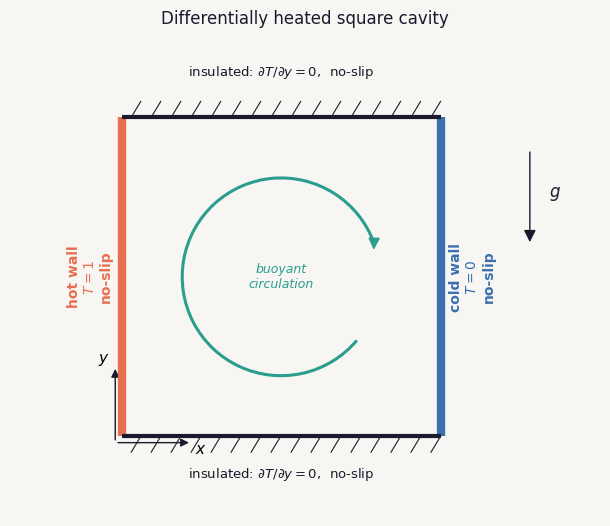

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Arc

BG="#f7f6f2"; HOT="#E76F51"; COLD="#3B6FB0"; INK="#1A1A2E"; TEAL="#2A9D8F"
fig, ax = plt.subplots(figsize=(6.2, 6.2)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
ax.plot([0,0],[0,1], color=HOT,  lw=6, solid_capstyle='butt')
ax.plot([1,1],[0,1], color=COLD, lw=6, solid_capstyle='butt')
ax.plot([0,1],[1,1], color=INK,  lw=3, solid_capstyle='butt')
ax.plot([0,1],[0,0], color=INK,  lw=3, solid_capstyle='butt')
for xx in np.linspace(0.03, 0.97, 16):
    ax.plot([xx, xx+0.03], [1.0, 1.05], color=INK, lw=0.8)
    ax.plot([xx, xx+0.03], [-0.05, 0.0], color=INK, lw=0.8)
ax.text(-0.10,0.5,"hot wall\n$T=1$\nno-slip",color=HOT,ha='center',va='center',fontsize=10,rotation=90,weight='bold')
ax.text(1.10,0.5,"cold wall\n$T=0$\nno-slip",color=COLD,ha='center',va='center',fontsize=10,rotation=90,weight='bold')
ax.text(0.5,1.13,r"insulated: $\partial T/\partial y=0$,  no-slip",color=INK,ha='center',fontsize=9.5)
ax.text(0.5,-0.13,r"insulated: $\partial T/\partial y=0$,  no-slip",color=INK,ha='center',fontsize=9.5)
ax.add_patch(Arc((0.5,0.5),0.62,0.62,angle=0,theta1=20,theta2=320,color=TEAL,lw=2.2))
th=np.deg2rad(20)
ax.add_patch(FancyArrowPatch((0.5+0.31*np.cos(th),0.5+0.31*np.sin(th)),
    (0.5+0.31*np.cos(th)-0.001,0.5+0.31*np.sin(th)-0.03),arrowstyle='-|>',mutation_scale=18,color=TEAL))
ax.text(0.5,0.5,"buoyant\ncirculation",color=TEAL,ha='center',va='center',fontsize=9,style='italic')
ax.add_patch(FancyArrowPatch((1.28,0.9),(1.28,0.6),arrowstyle='-|>',mutation_scale=18,color=INK))
ax.text(1.34,0.75,"$g$",color=INK,fontsize=12)
ax.add_patch(FancyArrowPatch((-0.02,-0.02),(0.22,-0.02),arrowstyle='-|>',mutation_scale=12,color=INK))
ax.add_patch(FancyArrowPatch((-0.02,-0.02),(-0.02,0.22),arrowstyle='-|>',mutation_scale=12,color=INK))
ax.text(0.23,-0.055,"$x$",fontsize=11); ax.text(-0.075,0.23,"$y$",fontsize=11)
ax.set_xlim(-0.35,1.5); ax.set_ylim(-0.25,1.25); ax.set_aspect('equal'); ax.axis('off')
ax.set_title("Differentially heated square cavity", color=INK, fontsize=12, pad=10)
plt.tight_layout()
plt.savefig("differentially_heated_cavity.png", dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

---

## 3 — Imports and setup

Same three libraries as every tutorial in the series — `torch`, `numpy`, `matplotlib` — a seed, and automatic GPU selection. The constants block holds the two dimensionless numbers from Section 2. Because the equations are already **non-dimensional**, every field is $O(1)$ by construction: $T\in[0,1]$, and the velocities scale with $Ra$ but stay well-behaved at the values we use. That's the same "keep everything $O(1)$ so training is stable" discipline as Tutorial 3's non-dimensionalization — here it comes for free from the Boussinesq scaling.

`RA` is the dial. We set it to $10^4$ for the main run; changing this single number is the whole "watch the PINN strain" experiment later — crank it to $10^5$ and the boundary layers thin until the network struggles.

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

RA = 1.0e4        # Rayleigh number  -> the dial
PR = 0.71         # Prandtl number   -> air; fixed to match the benchmark
RA_PR = RA * PR   # buoyancy coefficient, reused in the vorticity residual
PI = math.pi
print(f"Ra = {RA:.0e}, Pr = {PR}")

Using device: cpu
Ra = 1e+04, Pr = 0.71


---

## 4 — The reference: benchmark values + diagnostics

No analytical field exists, so the reference is a table of scalars plus the functions that extract the same scalars from our PINN. Values are the de Vahl Davis (1983) benchmark for $Pr=0.71$ (as tabulated and reproduced by Fowler et al. 2024): the average Nusselt number on the hot wall, the peak horizontal velocity on the vertical mid-plane, and the peak vertical velocity on the horizontal mid-plane.

The diagnostic functions reference `model` and `fields`, defined in Sections 5–6; Python resolves those names at call time, so defining the diagnostics here is fine.

In [3]:
# de Vahl Davis (1983), Pr = 0.71 (as reproduced in Fowler, McDevitt & Roy 2024)
BENCHMARK = {
    1e3: dict(Nu=1.118, u_max=3.649,  v_max=3.697),
    1e4: dict(Nu=2.243, u_max=16.178, v_max=19.617),
    1e5: dict(Nu=4.519, u_max=34.730, v_max=68.590),
}

def nusselt_hot_wall(n=200):
    "Average Nusselt number on the hot wall (x=0): mean of -dT/dx."
    y = torch.linspace(0, 1, n, device=device).reshape(-1, 1)
    x = torch.zeros_like(y).requires_grad_(True)
    _, T = fields(x, y)
    T_x = torch.autograd.grad(T, x, torch.ones_like(T))[0]
    return (-T_x).mean().item()

def peak_velocities(n=200):
    "u_max on the vertical mid-plane (x=0.5); v_max on the horizontal mid-plane (y=0.5)."
    y = torch.linspace(0, 1, n, device=device).reshape(-1, 1).requires_grad_(True)
    x = torch.full_like(y, 0.5)
    psi, _ = fields(x, y)
    u = torch.autograd.grad(psi, y, torch.ones_like(psi))[0]     # u = dpsi/dy
    u_max = u.abs().max().item()
    x2 = torch.linspace(0, 1, n, device=device).reshape(-1, 1).requires_grad_(True)
    y2 = torch.full_like(x2, 0.5)
    psi2, _ = fields(x2, y2)
    v = -torch.autograd.grad(psi2, x2, torch.ones_like(psi2))[0] # v = -dpsi/dx
    v_max = v.abs().max().item()
    return u_max, v_max

print(f"Benchmark target @ Ra = {RA:.0e}: {BENCHMARK[RA]}")

Benchmark target @ Ra = 1e+04: {'Nu': 2.243, 'u_max': 16.178, 'v_max': 19.617}


---

## 5 — Collocation and boundary points

Because no-slip and the hot/cold temperatures are hard-constrained, we need collocation points only for (a) the **interior** residuals and (b) the **insulated top/bottom walls** (the one soft BC). Following Fowler et al., points are uniform random; we use fewer than their 10,000 to keep a single step affordable — increase `N_f` for production accuracy.

In [4]:
gen = torch.Generator().manual_seed(42)
def rc(n): return torch.rand(n, 1, generator=gen)

N_f = 4000                                   # interior collocation points
x_f = rc(N_f).to(device).requires_grad_(True)
y_f = rc(N_f).to(device).requires_grad_(True)

N_w = 200                                    # insulated-wall points (top & bottom)
x_bot = rc(N_w).to(device); y_bot = torch.zeros(N_w, 1, device=device).requires_grad_(True)
x_top = rc(N_w).to(device); y_top = torch.ones (N_w, 1, device=device).requires_grad_(True)

print(f"interior: {N_f}  |  insulated-wall points: {2*N_w}")

interior: 4000  |  insulated-wall points: 400


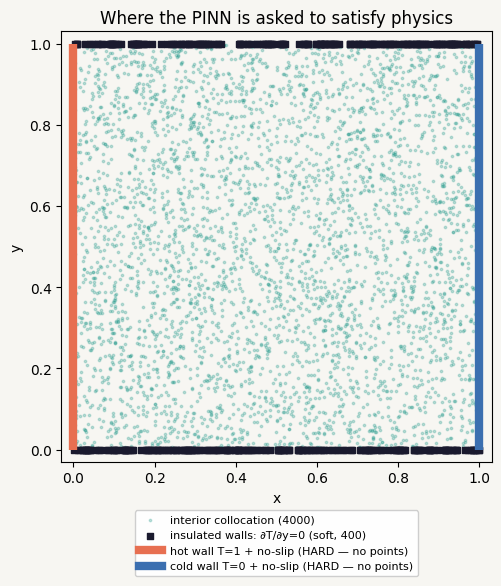

In [5]:
def np2(t):
    return t.detach().cpu().numpy()

HOT="#E76F51"; COLD="#3B6FB0"; INK="#1A1A2E"; TEAL="#2A9D8F"; BG="#f7f6f2"
plt.figure(figsize=(6.0, 6.0)); plt.gca().set_facecolor(BG); plt.gcf().patch.set_facecolor(BG)

# interior collocation points (for the residuals)
plt.scatter(np2(x_f), np2(y_f), s=3, alpha=0.28, color=TEAL, label=f"interior collocation ({N_f})")

# insulated top/bottom walls — the only soft BC, so the only walls needing points
plt.scatter(np2(x_bot), np2(y_bot), s=14, color=INK, marker="s", label=f"insulated walls: ∂T/∂y=0 (soft, {2*N_w})")
plt.scatter(np2(x_top), np2(y_top), s=14, color=INK, marker="s")

# hot/cold walls are HARD-constrained (baked into the architecture) -> no collocation points
plt.plot([0,0],[0,1], color=HOT,  lw=6, solid_capstyle='butt')
plt.plot([1,1],[0,1], color=COLD, lw=6, solid_capstyle='butt')
plt.plot([], [], color=HOT,  lw=6, label="hot wall T=1 + no-slip (HARD — no points)")
plt.plot([], [], color=COLD, lw=6, label="cold wall T=0 + no-slip (HARD — no points)")

plt.xlabel("x"); plt.ylabel("y")
plt.title("Where the PINN is asked to satisfy physics")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=1, framealpha=0.95, fontsize=8)
plt.gca().set_aspect("equal"); plt.xlim(-0.03, 1.03); plt.ylim(-0.03, 1.03)
plt.tight_layout()
plt.savefig("collocation_points.png", dpi=300, bbox_inches='tight', facecolor=plt.gcf().get_facecolor())
plt.show()

---

## 6 — The network

Two outputs: $\psi_0$ and $T_0$, the *raw* network outputs that Section 7 turns into the constrained $\psi$ and $T$. Following Fowler et al., the 2D architecture is **7 hidden layers of 64** with `tanh` (smooth — we need up to 4th derivatives), no output activation, Xavier init.

Everything else is unchanged from Tutorial 3. **`tanh`** activations, because the residuals need *second* derivatives (the viscous and diffusive Laplacians), so the network must be smooth to second order. The `n_hidden` / `n_layers` parametrization is the same.

In [6]:
class PINN(nn.Module):
    "Input (x, y) -> raw outputs (psi0, T0)."
    def __init__(self, n_hidden=64, n_layers=7):
        super().__init__()
        layers = [nn.Linear(2, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_hidden, n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden, 2)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self, x, y):
        out = self.net(torch.cat([x, y], dim=1))
        return out[:, 0:1], out[:, 1:2]     # psi0, T0

model = PINN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")

PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=64, bias=True)
    (9): Tanh()
    (10): Linear(in_features=64, out_features=64, bias=True)
    (11): Tanh()
    (12): Linear(in_features=64, out_features=64, bias=True)
    (13): Tanh()
    (14): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 25282


---

## 7 — Hard constraints (the key to convergence)

Instead of penalizing the walls with loss terms, we **build the boundary conditions into the outputs**, so they hold exactly, for free — and the network only has to learn the interior. This is the single most important trick for making natural convection converge.

**No-slip, all four walls.** No-slip means both velocity components vanish on every wall, i.e. $\psi$ **and** its normal derivative are zero there. Multiply the raw output by the square of a function that vanishes on the boundary:

$$b(x,y)=16\,x(1-x)\,y(1-y),\qquad \psi=b^2\,\psi_0.$$

Because $b=0$ on every wall, $\psi=0$ there; and because it's *squared*, $\nabla\psi=0$ there too — so $u=v=0$ on all walls automatically.

**Hot/cold temperatures.** A lift that already satisfies the end walls, plus a learnable interior correction that vanishes on them:

$$T=\underbrace{(1-x)}_{\text{linear lift}}+\underbrace{\sin(\pi x)}_{=0\text{ at }x=0,1}\,T_0.$$

At $x=0$: $T=1$. At $x=1$: $T=0$. Exactly, always. Only the insulated top/bottom walls remain for the loss.

In [7]:
def fields(x, y):
    "Turn raw network outputs into constrained (psi, T)."
    psi0, T0 = model(x, y)
    b = 16 * x * (1 - x) * y * (1 - y)
    psi = b**2 * psi0                       # hard no-slip: psi = 0 and grad(psi) = 0 on all walls
    T = (1 - x) + torch.sin(PI * x) * T0    # hard hot/cold: T = 1 at x=0, T = 0 at x=1
    return psi, T

In [8]:
def _grad(o, i): 
    return torch.autograd.grad(o, i, torch.ones_like(o), create_graph=True)[0]

yb = torch.linspace(0, 1, 20, device=device).reshape(-1, 1)
_, T0w = fields(torch.zeros_like(yb), yb)
_, T1w = fields(torch.ones_like(yb),  yb)
print(f"T at x=0 (want 1): {T0w.min().item():.4f}..{T0w.max().item():.4f}")
print(f"T at x=1 (want 0): {T1w.min().item():.4f}..{T1w.max().item():.4f}")
xc = torch.zeros(30, 1, device=device, requires_grad=True)
yc = torch.rand(30, 1, device=device, requires_grad=True)
psi, _ = fields(xc, yc)
print(f"no-slip at x=0: max|u|={_grad(psi,yc).abs().max().item():.2e}  max|v|={_grad(psi,xc).abs().max().item():.2e}")

T at x=0 (want 1): 1.0000..1.0000
T at x=1 (want 0): 0.0000..0.0000
no-slip at x=0: max|u|=0.00e+00  max|v|=0.00e+00


---

## 8 — The residuals: vorticity transport + energy

Two residuals. From $\psi$ we build velocity ($u=\psi_y$, $v=-\psi_x$) and vorticity ($\zeta=-\nabla^2\psi$); then:

$$
\begin{aligned}
f_1 &= u\,\zeta_x + v\,\zeta_y - Pr\,\nabla^2\zeta - Ra\,Pr\,T_x \quad&&(\text{vorticity transport})\\
f_3 &= u\,T_x + v\,T_y - \nabla^2 T \quad&&(\text{energy})
\end{aligned}
$$

The $\psi$–$\zeta$ relation $\nabla^2\psi+\zeta=0$ is satisfied *by definition* (we set $\zeta=-\nabla^2\psi$), so it needs no residual. Note $\nabla^2\zeta$ makes this a **fourth-order** derivative of $\psi$.

In [9]:
def grad(o, i): 
    return torch.autograd.grad(o, i, torch.ones_like(o), create_graph=True)[0]

def residuals(x, y):
    psi, T = fields(x, y)
    psi_x, psi_y = grad(psi, x), grad(psi, y)
    u, v = psi_y, -psi_x                          # continuity exact by construction
    psi_xx, psi_yy = grad(psi_x, x), grad(psi_y, y)
    zeta = -(psi_xx + psi_yy)                     # vorticity
    zeta_x, zeta_y = grad(zeta, x), grad(zeta, y)
    lap_zeta = grad(zeta_x, x) + grad(zeta_y, y)  # 4th-order in psi
    T_x, T_y = grad(T, x), grad(T, y)
    lap_T = grad(T_x, x) + grad(T_y, y)
    f1 = u*zeta_x + v*zeta_y - PR*lap_zeta - RA_PR*T_x   # vorticity transport
    f3 = u*T_x + v*T_y - lap_T                           # energy
    return f1, f3

---

## 9 — The composite loss

The vorticity residual is divided by $Ra$ before squaring (Fowler et al.) to stop the large buoyancy scale from dominating — the vorticity-formulation analog of the momentum scaling we discussed. The only boundary term is the insulated top/bottom ($\partial T/\partial y=0$).

In [10]:
def compute_losses():
    f1, f3 = residuals(x_f, y_f)
    loss_pde = ((f1 / RA)**2).mean() + (f3**2).mean()   # vorticity residual scaled by Ra
    _, T_b = fields(x_bot, y_bot); ty_b = grad(T_b, y_bot)
    _, T_t = fields(x_top, y_top); ty_t = grad(T_t, y_top)
    loss_bc = (ty_b**2).mean() + (ty_t**2).mean()       # insulated walls (soft)
    return loss_pde, loss_bc

def total_loss():
    lp, lb = compute_losses()
    return lp + lb

lp, lb = compute_losses()
print(f"untrained:  loss_pde={lp.item():.3e}  loss_bc={lb.item():.3e}")

untrained:  loss_pde=6.967e+00  loss_bc=1.644e-02


---

## 10 — Two-phase training: Adam → L-BFGS

A short Adam warm-up, then L-BFGS (the workhorse for this problem — Fowler et al. rely on it). We log the loss and the three benchmark diagnostics so you can watch convection **develop**: `u_max` and `v_max` climb from ~0, and `Nu` lifts off 1 toward 2.243 as the flow strengthens.

**This is a heavy solve** — 4th-order autograd, and convection takes many L-BFGS iterations to appear. On CPU it crawls; on a GPU it's far more comfortable. Increase the L-BFGS `max_iter` / rounds until the diagnostics plateau near the benchmark. If the flow is slow to start, that's expected — it develops gradually, not suddenly.

In [11]:
history = {"epoch": [], "pde": [], "bc": [], "Nu": [], "u_max": [], "v_max": []}

def record(epoch):
    lp, lb = compute_losses(); um, vm = peak_velocities()
    history["epoch"].append(epoch); history["pde"].append(lp.item()); history["bc"].append(lb.item())
    history["Nu"].append(nusselt_hot_wall()); history["u_max"].append(um); history["v_max"].append(vm)
    print(f"[{epoch:5d}]  pde={lp.item():.3e} bc={lb.item():.3e}  "
          f"Nu={history['Nu'][-1]:.3f}  u_max={um:.3f}  v_max={vm:.3f}")

# --- Adam warm-up ---
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
ADAM_ITERS = 500
record(0)
for epoch in range(1, ADAM_ITERS + 1):
    opt.zero_grad(); total_loss().backward(); opt.step()
    if epoch % 100 == 0: record(epoch)

# --- L-BFGS refinement (run several rounds; increase until diagnostics plateau) ---
LBFGS_ROUNDS, LBFGS_ITERS = 20, 200
step = ADAM_ITERS
for r in range(LBFGS_ROUNDS):
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS_ITERS, max_eval=int(LBFGS_ITERS*1.3),
                            tolerance_grad=1e-12, tolerance_change=1e-14,
                            history_size=50, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad(); L = total_loss(); L.backward(); return L
    opt.step(closure); step += LBFGS_ITERS
    record(step)
print("done — compare the final Nu / u_max / v_max against BENCHMARK[RA]")

[    0]  pde=6.967e+00 bc=1.644e-02  Nu=1.258  u_max=1.081  v_max=1.121
[  100]  pde=5.038e-01 bc=5.663e-05  Nu=1.004  u_max=0.073  v_max=0.089
[  200]  pde=5.036e-01 bc=5.078e-05  Nu=1.001  u_max=0.069  v_max=0.078
[  300]  pde=5.035e-01 bc=4.524e-05  Nu=1.001  u_max=0.067  v_max=0.074
[  400]  pde=5.033e-01 bc=4.087e-05  Nu=1.000  u_max=0.069  v_max=0.077
[  500]  pde=5.032e-01 bc=3.640e-05  Nu=1.000  u_max=0.071  v_max=0.082
[  700]  pde=4.248e-01 bc=1.167e-03  Nu=1.010  u_max=0.783  v_max=1.517
[  900]  pde=3.529e-01 bc=3.881e-03  Nu=1.091  u_max=4.521  v_max=3.328
[ 1100]  pde=3.017e-01 bc=3.649e-03  Nu=1.143  u_max=6.449  v_max=4.129
[ 1300]  pde=2.628e-01 bc=2.179e-03  Nu=1.292  u_max=7.959  v_max=6.833
[ 1500]  pde=1.974e-01 bc=3.531e-03  Nu=1.499  u_max=8.989  v_max=10.067
[ 1700]  pde=1.310e-01 bc=5.327e-03  Nu=1.899  u_max=12.010  v_max=15.352
[ 1900]  pde=1.043e-01 bc=1.647e-03  Nu=1.900  u_max=11.760  v_max=15.055
[ 2100]  pde=8.440e-02 bc=1.907e-03  Nu=2.034  u_max=13.397

---

## 11 — The loss history, both phases

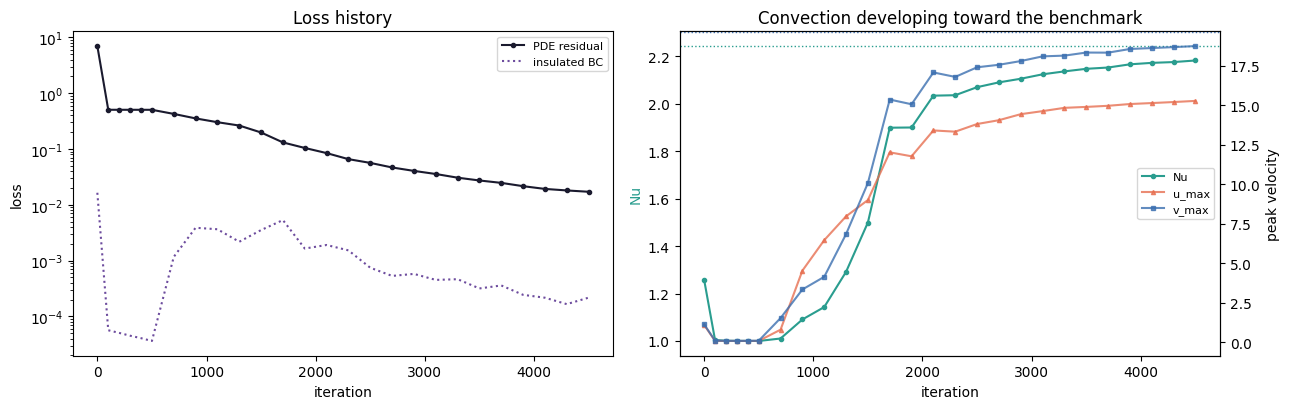

In [12]:
# convergence history: watch convection develop
epoch = np.array(history["epoch"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].semilogy(epoch, history["pde"], 'o-', color='#1A1A2E', ms=3, label='PDE residual')
ax[0].semilogy(epoch, np.maximum(history["bc"],1e-14), ':', color='#6D4C9E', label='insulated BC')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss'); ax[0].set_title('Loss history'); ax[0].legend(fontsize=8)
ax2 = ax[1]; ax3 = ax2.twinx()
ax2.plot(epoch, history["Nu"], 'o-', color='#2A9D8F', ms=3, label='Nu')
ax2.axhline(BENCHMARK[RA]['Nu'], ls=':', color='#2A9D8F', lw=1)
ax3.plot(epoch, history["u_max"], '^-', color='#E76F51', ms=3, alpha=0.8, label='u_max')
ax3.plot(epoch, history["v_max"], 's-', color='#3B6FB0', ms=3, alpha=0.8, label='v_max')
ax3.axhline(BENCHMARK[RA]['v_max'], ls=':', color='#3B6FB0', lw=1)
ax2.set_xlabel('iteration'); ax2.set_ylabel('Nu', color='#2A9D8F'); ax3.set_ylabel('peak velocity')
ax2.set_title('Convection developing toward the benchmark')
h1,l1=ax2.get_legend_handles_labels(); h2,l2=ax3.get_legend_handles_labels()
ax2.legend(h1+h2, l1+l2, fontsize=8, loc='center right')
plt.tight_layout()
plt.savefig("convergence_history.png", dpi=300, bbox_inches='tight', facecolor=plt.gcf().get_facecolor())
plt.show()

---

## 12 — Results and validation

Compare the trained diagnostics against the benchmark,then plot the fields.

In [13]:
um, vm = peak_velocities()
b = BENCHMARK[RA]
print(f"quantity     PINN        de Vahl Davis   rel. error")
print(f"Nu          {nusselt_hot_wall():8.3f}    {b['Nu']:8.3f}      {abs(nusselt_hot_wall()-b['Nu'])/b['Nu']*100:5.1f}%")
print(f"u_max       {um:8.3f}    {b['u_max']:8.3f}      {abs(um-b['u_max'])/b['u_max']*100:5.1f}%")
print(f"v_max       {vm:8.3f}    {b['v_max']:8.3f}      {abs(vm-b['v_max'])/b['v_max']*100:5.1f}%")

quantity     PINN        de Vahl Davis   rel. error
Nu             2.182       2.243        2.7%
u_max         15.267      16.178        5.6%
v_max         18.738      19.617        4.5%


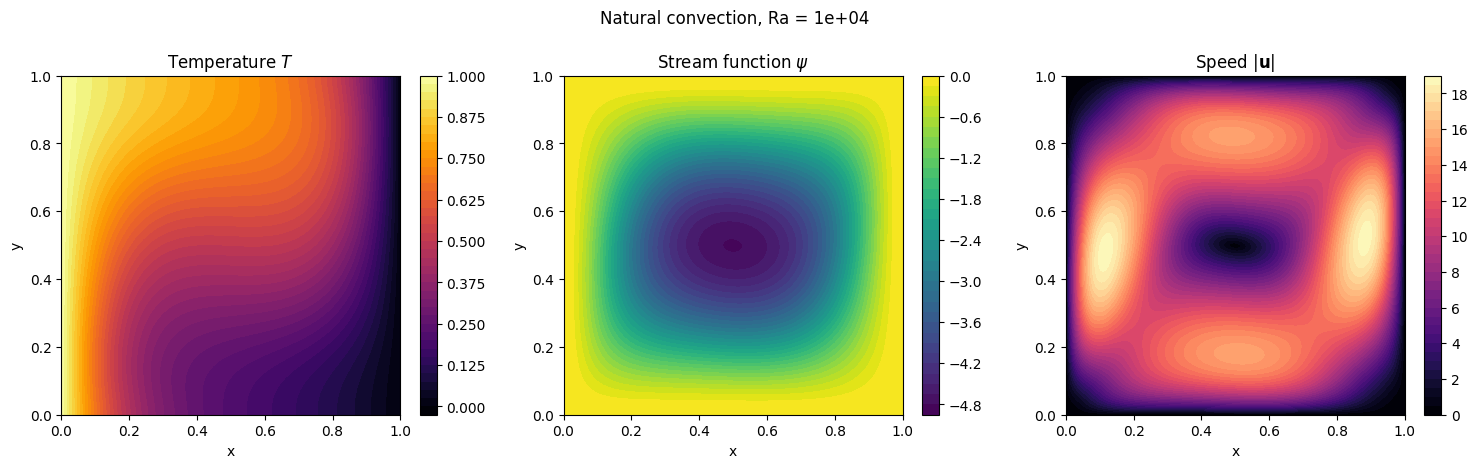

In [14]:
# field contours: temperature, stream function, velocity magnitude
n = 200
gx = torch.linspace(0, 1, n, device=device)
X, Y = torch.meshgrid(gx, gx, indexing='ij')
xf = X.reshape(-1,1).requires_grad_(True); yf = Y.reshape(-1,1).requires_grad_(True)
psi, T = fields(xf, yf)
u = grad(psi, yf); v = -grad(psi, xf)
speed = torch.sqrt(u**2 + v**2)
def G(t): return t.detach().reshape(n, n).cpu().numpy()
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a, (D, ttl, cm) in zip(ax, [(G(T),'Temperature $T$','inferno'),
                                (G(psi),'Stream function $\\psi$','viridis'),
                                (G(speed),'Speed $|\\mathbf{u}|$','magma')]):
    cf = a.contourf(Xn, Yn, D, levels=40, cmap=cm); fig.colorbar(cf, ax=a, fraction=0.046)
    a.set_title(ttl); a.set_xlabel('x'); a.set_ylabel('y'); a.set_aspect('equal')
plt.suptitle(f'Natural convection, Ra = {RA:.0e}', y=1.02)
plt.tight_layout()
plt.savefig("field_contours.png", dpi=300, bbox_inches='tight', facecolor=plt.gcf().get_facecolor())
plt.show()

- **Why this converges and the primitive form doesn't.** Continuity is exact, pressure is gone, and no-slip + wall temperatures are hard-constrained — so the optimizer only has to find the interior circulation, not fight a huge pressure or discover flow from a dead-flat start. The conduction trap that stops $(u,v,p,T)$ is sidestepped by construction.
- **It develops gradually.** Convection appears as a slow, monotonic climb in `u_max`/`v_max` over many L-BFGS iterations, with `Nu` lifting off 1 only once the flow is strong enough to distort the temperature field. If your diagnostics are short of the benchmark, **train longer** (more L-BFGS rounds) before concluding anything.
- **Higher $Ra$ is harder.** At $Ra=10^5$–$10^6$ the boundary layers thin and Fowler et al. report the optimizer briefly converging to a *sign-flipped* wrong solution before finding the right one. Expect longer training and add interior points.
- **Reference.** Formulation and PINN benchmark: Fowler, McDevitt & Roy, *Sci. Rep.* **14**, 15203 (2024). Underlying CFD benchmark: de Vahl Davis, *Int. J. Numer. Methods Fluids* **3**, 249–264 (1983).


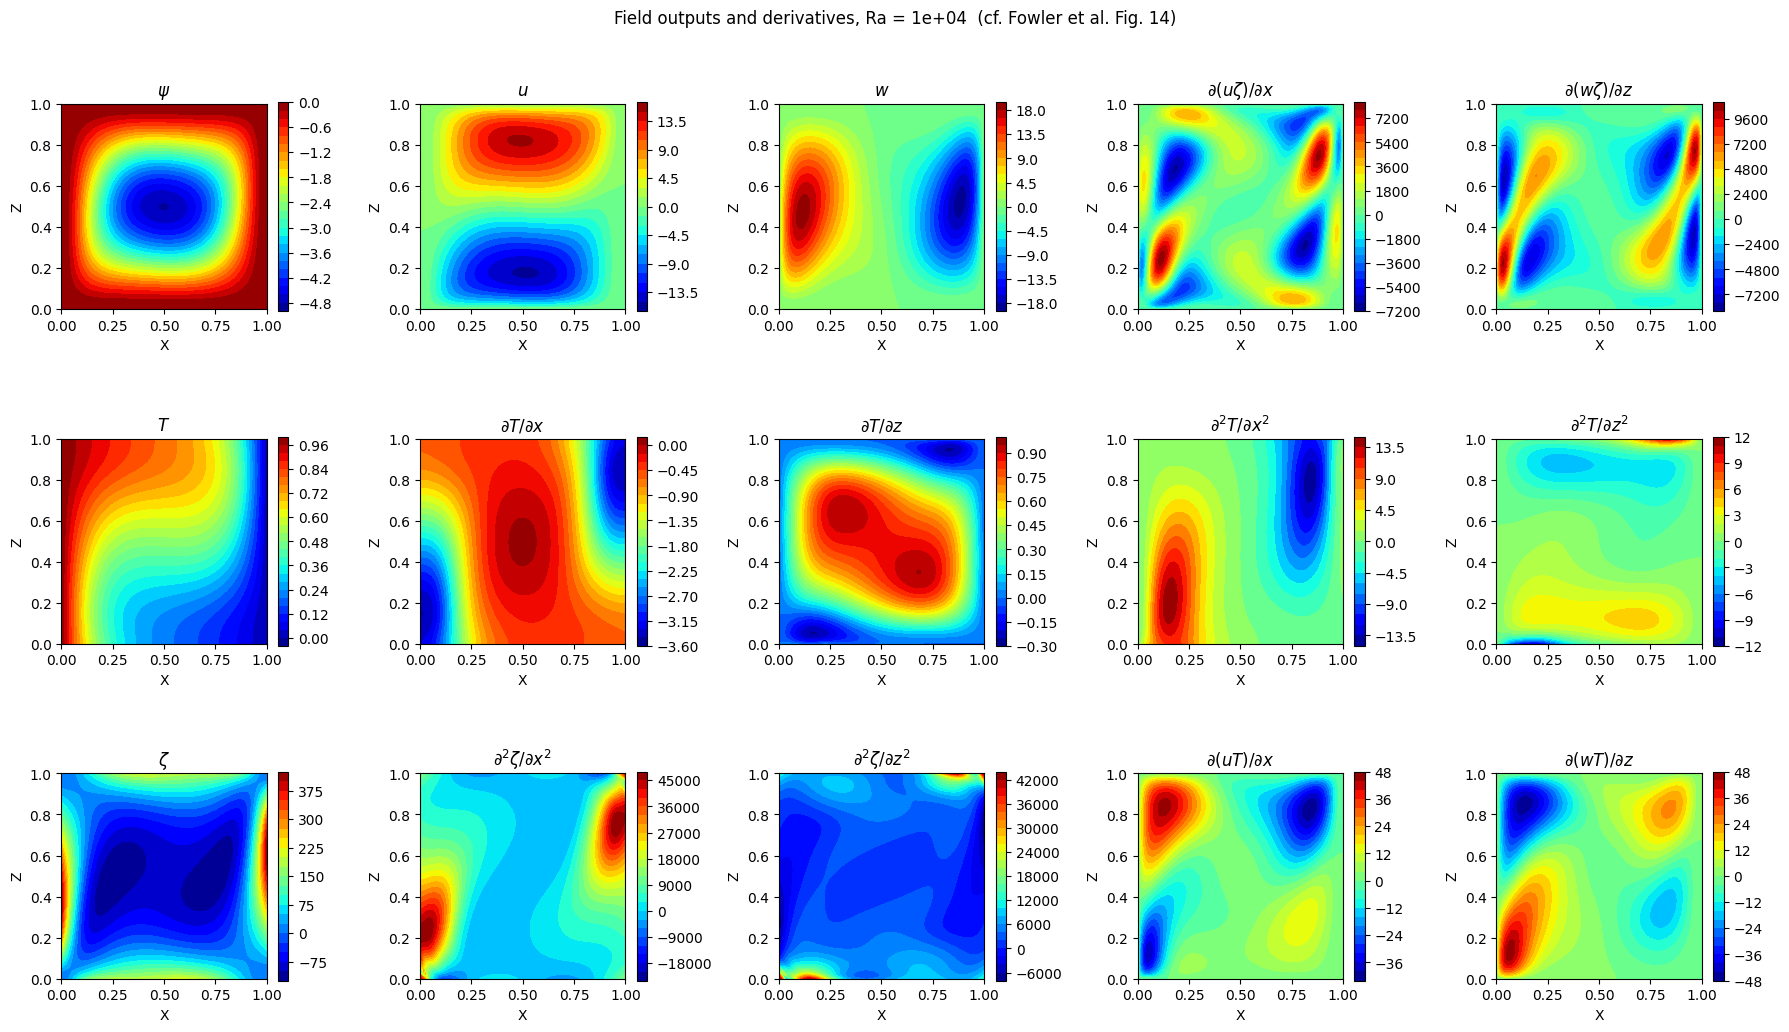

In [15]:
# --- Figure-14-style panel: all fields & derivatives from the trained (psi, T) ---
# Everything here is a SPATIAL derivative of the model's own outputs — no retraining.
# (Paper uses z for vertical; here that's y. Axes labelled X/Z to match the paper.)
n = 120                                    # GPU: 120 is fine; on CPU drop to ~50 (memory/time)
gx = torch.linspace(0, 1, n, device=device)
X, Y = torch.meshgrid(gx, gx, indexing='ij')
x = X.reshape(-1,1).requires_grad_(True); y = Y.reshape(-1,1).requires_grad_(True)

psi, T = fields(x, y)
psi_x, psi_y = grad(psi, x), grad(psi, y)
u, w = psi_y, -psi_x                        # u horizontal, w vertical
psi_xx, psi_yy = grad(psi_x, x), grad(psi_y, y)
zeta = -(psi_xx + psi_yy)
zeta_x, zeta_y = grad(zeta, x), grad(zeta, y)
zeta_xx, zeta_yy = grad(zeta_x, x), grad(zeta_y, y)
T_x, T_y = grad(T, x), grad(T, y)
T_xx, T_yy = grad(T_x, x), grad(T_y, y)
d_uzeta_x, d_wzeta_y = grad(u*zeta, x), grad(w*zeta, y)
d_uT_x,   d_wT_y     = grad(u*T, x),   grad(w*T, y)

def G(t): return t.detach().reshape(n, n).cpu().numpy()
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

panels = [
    (psi, r'$\psi$'), (u, r'$u$'), (w, r'$w$'),
        (d_uzeta_x, r'$\partial(u\zeta)/\partial x$'), (d_wzeta_y, r'$\partial(w\zeta)/\partial z$'),
    (T, r'$T$'), (T_x, r'$\partial T/\partial x$'), (T_y, r'$\partial T/\partial z$'),
        (T_xx, r'$\partial^2 T/\partial x^2$'), (T_yy, r'$\partial^2 T/\partial z^2$'),
    (zeta, r'$\zeta$'), (zeta_xx, r'$\partial^2\zeta/\partial x^2$'), (zeta_yy, r'$\partial^2\zeta/\partial z^2$'),
        (d_uT_x, r'$\partial(uT)/\partial x$'), (d_wT_y, r'$\partial(wT)/\partial z$'),
]
fig, ax = plt.subplots(3, 5, figsize=(18, 10.5))
for a, (D, t) in zip(ax.flat, panels):
    cf = a.contourf(Xn, Yn, G(D), levels=25, cmap='jet'); fig.colorbar(cf, ax=a, fraction=0.046)
    a.set_title(t, fontsize=12); a.set_xlabel('X'); a.set_ylabel('Z'); a.set_aspect('equal')
plt.suptitle(f'Field outputs and derivatives, Ra = {RA:.0e}  (cf. Fowler et al. Fig. 14)', y=1.0)
plt.tight_layout()
plt.savefig("field_outputs_and_derivatives.png", dpi=300, bbox_inches='tight', facecolor=plt.gcf().get_facecolor())
plt.show()

---

## 13 — Exercises

1. **Turn the Rayleigh dial down.** Set `RA = 1e3` and retrain. Convection is gentler here, so it converges faster and more reliably — a good confidence-builder. Check your Nusselt number against the benchmark's 1.118 and the peak velocities against 3.649 / 3.697. This is the run to do *first* if your `Ra=1e4` solve is being stubborn.
2. **Watch the conduction trap yourself.** Temporarily replace the hard temperature constraint `T = (1-x) + sin(πx)·T0` with a plain network output `T = T0` plus *soft* loss terms for `T=1` at `x=0` and `T=0` at `x=1`. Retrain and watch `u_max`, `v_max` sit near zero — you've reintroduced the trap. Restoring the hard constraint fixes it. Nothing teaches why the formulation matters like breaking it on purpose.
3. **Push Ra up until it strains.** Take `RA` to `1e5`, then `1e6`. The thermal boundary layers thin (roughly like `Ra^{-1/4}`), so you'll need more interior points near the walls and many more L-BFGS iterations. Fowler et al. report the optimizer briefly converging to a *sign-flipped* wrong solution at high Ra before finding the right one — if your circulation comes out reversed early in training, that's the documented failure, not a bug. Report how far you get, and how the training budget scales with Ra. This is the honest on-ramp to the "PINNs and turbulence" question.
4. **Buy accuracy with points and iterations.** Raise `N_f` from 4000 toward the paper's 10,000, and increase `LBFGS_ROUNDS`. Plot your Nu / u_max / v_max error against training budget. You'll find diminishing returns — a good, honest illustration of the accuracy-vs-cost trade every PINN forces.
5. **Reproduce Figure 14 (field derivatives).** Run the 15-panel cell — it needs *no retraining*, since every panel is a spatial derivative of your trained ψ and T. Compare the pattern (ψ splitting into two cells, the boundary-layer structure in `∂T/∂x`) against the paper. Note which high-order panels (`∂²ζ`) are "dominated by outliers," exactly as the paper warns.
6. **Parametric PINN + Figure 18 (Ra sensitivities).** The advanced extension: make the network take Ra as an input `(x, y, r)` with `r = log10(Ra)`, train across a Ra range, and recover `∂ψ/∂Ra`, `∂T/∂Ra`, etc. by autograd — a single network covering the whole Ra family, with parameter sensitivities for free. This is the one benchmark that genuinely can't be faked from a fixed-Ra model.
7. **Change the aspect ratio.** Make the cavity a tall or wide rectangle (rescale the domain and the hard-constraint factor `b`). The single central cell can break into stacked cells — a qualitatively new flow, still with the same code.
8. **Change the fluid.** Swap `Pr = 0.71` (air) for water (`Pr ≈ 7`) or a liquid metal (`Pr ≈ 0.025`). Watch how the relative thickness of the thermal and velocity boundary layers changes — high `Pr` sharpens the thermal layer, low `Pr` the velocity layer. (Benchmark values change too, so you'd need a matching reference.)

---

## 14 — Failure modes to watch for

This tutorial has more ways to fail than any before it, and the worst one is silent — the network *looks* converged while being physically wrong. The first two rows are the ones that define this problem.

| Symptom | Cause | Fix |
|---------|-------|-----|
| **Loss drops nicely, but `u_max ≈ v_max ≈ 0` and `Nu ≈ 1`** | the **conduction trap** — the network found the trivial no-flow solution, which nearly satisfies everything | this is *the* failure of the primitive-variable form. Use the stream-function/vorticity formulation with **hard constraints** — it sidesteps the trap by construction |
| Convection never starts, even with (ψ, T) | too few L-BFGS iterations — flow develops *slowly* | **keep training.** `u_max`/`v_max` climb gradually over many rounds; `Nu` lifts off 1 only once the flow is strong. Don't judge convergence at 500 iterations |
| Circulation runs the *wrong way* (mirror image) at high Ra | the documented sign-flipped local minimum (Fowler et al.) | train longer — it usually escapes; or restart from a lower-Ra warm start |
| `NaN` loss early in training | 4th-order derivatives amplify a bad init or too-high learning rate | lower the Adam LR; confirm `tanh` (not ReLU); check the hard-constraint factor `b` isn't mis-typed |
| `Nu` and velocities plateau *below* the benchmark | under-resolved boundary layers, especially as Ra rises | add interior points; densify near the walls; raise `N_f` toward the paper's 10,000 |
| Fields look right but the numbers are off | reading the wrong benchmark | `Pr` must be **0.71** to match de Vahl Davis; changing `Pr` or the scaling invalidates the reference |
| `∂²ζ` panels look like noise with a couple of extreme spikes | fourth derivatives of the network amplify small wiggles | expected — the paper calls these "dominated by outliers." Clip the color scale by percentile; don't treat it as a bug |
| Loss stalls in L-BFGS and won't move | line search stuck in a flat region | the round-based restart (fresh optimizer each round) resets the history and frees it |

---

## 15 — Vocabulary

- **Natural (free) convection** — fluid motion driven by buoyancy alone, from temperature-induced density differences; no pump or external flow.
- **Boussinesq approximation** — the standard simplification for buoyant flow: density is treated as constant everywhere *except* in the buoyancy term, where its temperature variation drives the motion.
- **Stream function ($\psi$)** — a scalar whose derivatives give the velocity ($u=\partial\psi/\partial y$, $v=-\partial\psi/\partial x$); using it makes continuity exact by construction and eliminates pressure.
- **Vorticity ($\zeta$)** — the local rotation of the fluid, $\zeta=-\nabla^2\psi$; the quantity the vorticity-transport equation evolves.
- **Vorticity–stream-function formulation** — recasting the flow in terms of $(\psi,\zeta)$ instead of $(u,v,p)$; trades pressure and continuity for one higher-order equation, and is what makes this problem converge.
- **Rayleigh number ($Ra$)** — the ratio of buoyancy to diffusive damping; the dial that sets how vigorous the convection is.
- **Prandtl number ($Pr$)** — the ratio of momentum to thermal diffusivity; a fluid property (0.71 for air) that sets the relative thickness of the velocity and thermal boundary layers.
- **Nusselt number ($Nu$)** — the non-dimensional wall heat flux; $Nu=1$ is pure conduction, and values above 1 measure how much convection enhances heat transfer.
- **Buoyancy term** — the $Ra\,Pr\,\partial T/\partial x$ source in the vorticity equation; the one coupling that lets temperature drive the flow.
- **Hard constraint** — enforcing a boundary condition by building it into the network's output (e.g. $\psi=b^2\psi_0$), so it holds *exactly* rather than as a penalized loss term.
- **Conduction trap** — the trivial no-flow solution (linear temperature, $Nu\approx1$) that a naive PINN converges to and gets stuck in; a stable, wrong local minimum.
- **Differentially heated cavity** — the benchmark geometry: a square with a hot wall, an opposite cold wall, and insulated top and bottom.

---

## 16 — What You Have Built (and Where the Series Goes)

The first three tutorials shared a comfortable secret: the obvious formulation worked. Write the physics, sample points, minimize. This one broke that. The obvious approach — predict $(u,v,p,T)$, penalize every equation — converges to a confident, physical-looking lie: the pure-conduction solution, zero flow, $Nu=1$. The whole tutorial was learning to *not* do the obvious thing.

What made it work wasn't more capacity or more training — it was **reformulating the problem** so the network couldn't fail:

| Choice | What it buys |
|--------|-------------|
| predict $\psi$ instead of $u,v$ | continuity satisfied **exactly**, for free |
| vorticity form ($\zeta=-\nabla^2\psi$) | pressure **eliminated** — no gauge, no $O(Ra\,Pr)$ term to represent |
| hard constraints ($\psi=b^2\psi_0$, $T=1{-}x{+}\sin\pi x\,T_0$) | no-slip and wall temperatures hold **by construction** |
| scale the vorticity residual by $Ra$ | the buoyancy scale stops dominating the loss |

Each row removes a way for the optimizer to get stuck. Together they turn an intractable problem into a solvable one — and the price was a fourth-order derivative ($\nabla^2\zeta=\nabla^4\psi$) and patience.

That's the deepest lesson the series has offered so far, and it extends the throughline. Tutorial 1 changed the *residual* and the recipe held; Tutorial 2 changed the *boundary term*; Tutorial 3 moved the *unknown upstream* of the equation. Here we changed the **unknowns themselves** — the network predicts a stream function it was never asked about, and the physical variables you actually want are all downstream of it. The recipe never changed. What changes, tutorial by tutorial, is how much art goes into setting the recipe up.

**Your result** *(fill in from your GPU run against the benchmark of $Nu=2.243$, $u_{\max}=16.178$, $v_{\max}=19.617$)*: the trained model recovered $Nu \approx$ ___, $u_{\max}\approx$ ___, $v_{\max}\approx$ ___ — within ___% of de Vahl Davis. And you watched it *earn* that: convection didn't appear all at once but grew slowly under L-BFGS, $Nu$ lifting off 1 only once the circulation was strong enough to bend the temperature field. The conduction trap that swallows the naive approach was sidestepped entirely — not by fighting it, but by choosing variables that can't fall into it.

**The honest verdict on this problem:** this is where PINNs are genuinely hard, and honesty demands saying so. A finite-volume CFD code solves the differentially heated cavity in seconds and matches the benchmark to more digits than we did, and it never gets trapped. This is not the problem where PINNs win on speed or accuracy. What they *do* offer here is the thing you saw in the Figure-14 panels and the parametric extension: every derivative of the solution — vorticity, heat flux, even the sensitivity to $Ra$ itself — falls out of the same network by autograd, mesh-free, differentiable end to end. That's a different currency than raw accuracy, and it's the one the finale problems will spend.

**Where this series goes next:** Tutorial 5 keeps the fourth-order derivative you just met — $\nabla^4\psi$ — but strips everything else away. The **Euler–Bernoulli beam** is a single 4th-order ODE, $EI\,w'''' = q$, the cleanest possible setting to see how a PINN handles high-order derivatives and the boundary conditions they demand (deflection, slope, moment, shear). After the four coupled fields of this tutorial, it will feel like a held breath — before Part I climbs its last two rungs: flow separation, and then time itself.

**And beyond Part I.** The three tutorials that follow flip the question entirely. Tutorial 8 hands you sparse noisy sensors and asks you to recover the *physics* rather than the field. Tutorial 9 trains one network across an entire family of operating conditions, and gets parameter sensitivities free from autograd. Tutorial 10 closes the series with two materials joined at an interface — and uses the same hard-constraint idea that rescued this notebook.

---

### Get the Notebooks

The full series — all ten tutorials, with plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

### References

- Fowler, E., McDevitt, C. J. & Roy, S. (2024). *Physics-informed neural network simulation of thermal cavity flow.* Scientific Reports **14**, 15203. — *the stream-function/vorticity formulation and hard-constraint approach adopted here; reference implementation at [github.com/cmcdevitt2/ThermalCavity](https://github.com/cmcdevitt2/ThermalCavity).*
- de Vahl Davis, G. (1983). *Natural convection of air in a square cavity: a bench mark numerical solution.* Int. J. Numer. Methods Fluids **3**, 249–264. — *the underlying CFD benchmark: Nusselt numbers and peak velocities.*
- Wang, S., Teng, Y. & Perdikaris, P. (2021). *Understanding and mitigating gradient flow pathologies in physics-informed neural networks.* SIAM J. Sci. Comput. **43**, A3055–A3081. — *loss-term scaling, the issue that makes the naive formulation fail here.*

*Next up: one equation, fourth order, and the cleanest boundary conditions in the series — the bending beam. — Rohit Raj · HalfQubiX*